# 01 – Download arXiv abstracts and build the dataset table

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ilaria-cesa/Txt_lab/blob/main/notebooks/01_download_and_build_dataset.ipynb)

Work in progress. This notebook runs the whole data pipeline:

1. downloads metadata and abstracts of arXiv papers with at least one of the corpus categories
   (cs.AI, cs.LG, stat.ML, cs.CL, cs.CV, cs.RO, cs.NE; primary or cross-listed) through the official
   arXiv API, window by window;
2. cleans them (duplicates, withdrawn papers, very short abstracts) and writes the final CSV table;
3. runs quick sanity checks on the table.

The heavy lifting is in `src/arxiv_ai_dataset.py`. Downloads are **resumable**: if the notebook is
interrupted, run the download cell again with the same parameters and it continues from the last
finished window (raw responses are cached, nothing is requested twice).

No text pre-processing is done here (no lowercasing, stemming, ...): it belongs to the project pipeline.

## 1. Configuration

Parameters still to be decided are marked `TODO`.

In [1]:
# --- Parameters ----------------------------------------------------------------------------
CONTACT = "your_email@gmail.com"   # put your e-mail: arXiv asks for an identifiable User-Agent

# A paper is in the corpus if it has at least one of these categories (primary or cross-listed)
CORPUS_CATEGORIES = ["cs.AI", "cs.LG", "stat.ML", "cs.CL", "cs.CV", "cs.RO", "cs.NE"]

START_DATE = "2015-01-01"      # TODO: first day to download (YYYY-MM-DD)
END_DATE = "2026-10-15"        # TODO: last day (inclusive); keep a few weeks before today,
                               #       recent papers can still be re-classified by moderators
WINDOW_DAYS = 7                # window length in days. With NO cap the window size does not change WHAT is
                               # downloaded (all papers), only how many requests are needed: 7 is much faster than 1
MAX_PER_WINDOW = 100_000       # no sampling cap: everything is downloaded (cut/sample later, in pandas)
SAMPLING = "first"             # irrelevant without a cap ("first" saves one request per window)
PAGE_SIZE = 500                # papers per HTTP request (the API allows up to 2000)
MIN_WORDS = 30                 # abstracts shorter than this are dropped
SEED = 42

OUTPUT_CSV = "../data/arxiv_ai_abstracts.csv"
CACHE_DIR = "../data/arxiv_cache"
CHECKPOINT_EVERY = 100         # also save a partial CSV every N finished windows (0 = off)
EXCEL_FRIENDLY = False         # True: ';'-separated CSV with BOM (double-click in Excel with Italian settings)
EXTRA_ARGS = []                # extra command-line options of the script, if needed

### Optional: run on Google Colab (data saved on Google Drive)

The download needs **no GPU** and no heavy computation, only time. If you run it on Colab, the cell below mounts
Google Drive and stores the cache and the CSV there, so everything survives a disconnection or a change of Google
account (share the Drive folder, or download the CSV). Every finished window is saved immediately, and a partial CSV
is refreshed every `CHECKPOINT_EVERY` windows. Outside Colab the cell does nothing. (Requires the repository to be pushed to GitHub.)

In [2]:
import os, subprocess, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.exists("/content/Txt_lab"):
        subprocess.run(["git", "clone", "https://github.com/ilaria-cesa/Txt_lab", "/content/Txt_lab"], check=True)
    os.chdir("/content/Txt_lab/notebooks")
    DATA_DIR = "/content/drive/MyDrive/Txt_lab_data"
    os.makedirs(DATA_DIR, exist_ok=True)
    OUTPUT_CSV = f"{DATA_DIR}/arxiv_ai_abstracts.csv"
    CACHE_DIR = f"{DATA_DIR}/arxiv_cache"
    print("Colab: data will be saved in", DATA_DIR)

Mounted at /content/drive
Colab: data will be saved in /content/drive/MyDrive/Txt_lab_data


## 2. Download and build the table

This cell can run for hours on the full period. The progress bar shows the estimated remaining time; interrupt the kernel at any time and re-run to resume.

In [3]:
import sys, json, pathlib
sys.path.insert(0, str(pathlib.Path("..") / "src"))
import arxiv_ai_dataset as ad

argv = [
    "--contact", CONTACT,
    "--start-date", START_DATE, "--end-date", END_DATE,
    "--window-days", str(WINDOW_DAYS), "--max-per-window", str(MAX_PER_WINDOW),
    "--corpus-categories", ",".join(CORPUS_CATEGORIES),
    "--sampling", SAMPLING, "--page-size", str(PAGE_SIZE), "--seed", str(SEED), "--min-words", str(MIN_WORDS),
    "--checkpoint-every", str(CHECKPOINT_EVERY),
    "--output", OUTPUT_CSV, "--cache-dir", CACHE_DIR,
] + (["--excel"] if EXCEL_FRIENDLY else []) + list(EXTRA_ARGS)

assert "@" in CONTACT and "your.email" not in CONTACT, "set CONTACT to your real e-mail (arXiv asks for it)"
return_code = ad.main(argv)
print("return code:", return_code, "(0 = ok, 1 = error, 130 = interrupted; re-run to resume)")

09:41:30 INFO    Corpus categories: cs.AI, cs.LG, stat.ML, cs.CL, cs.CV, cs.RO, cs.NE


INFO:arxiv_ai:Corpus categories: cs.AI, cs.LG, stat.ML, cs.CL, cs.CV, cs.RO, cs.NE
INFO:arxiv_ai:Period 2015-01-01..2026-10-15 | 625 windows of <=7 days | 625 already done, 0 to do
INFO:arxiv_ai:Estimated worst case: ~0 requests, >= 0.0 hours at 3.2s/request (plus server latency)


09:41:30 INFO    Period 2015-01-01..2026-10-15 | 625 windows of <=7 days | 625 already done, 0 to do
09:41:30 INFO    Estimated worst case: ~0 requests, >= 0.0 hours at 3.2s/request (plus server latency)


windows: 100%|██████████| 625/625 [00:31<?, ?win/s]



SUMMARY
Cleaning: raw_records=643804, too_short=360, withdrawn=150, final=643294

Papers per year (final CSV)   [papers existing in API / fetched / coverage / truncated windows]
  2015:   6756      [   6775 /   6775 / 100.0% /  0]
  2016:  10620      [  10651 /  10651 / 100.0% /  0]
  2017:  15785      [  15822 /  15822 / 100.0% /  0]
  2018:  24058      [  24101 /  24101 / 100.0% /  0]
  2019:  34480      [  34530 /  34530 / 100.0% /  0]
  2020:  46192      [  46231 /  46231 / 100.0% /  0]
  2021:  51250      [  51282 /  51282 / 100.0% /  0]
  2022:  56664      [  56703 /  56703 / 100.0% /  0]
  2023:  71204      [  71230 /  71230 / 100.0% /  0]
  2024:  92192      [  92231 /  92231 / 100.0% /  0]
  2025: 113249      [ 113320 / 113320 / 100.0% /  0]
  2026: 120844      [ 120928 / 120928 / 100.0% /  0]
  TOTAL: 643294

Top-20 primary categories
  cs.CV              160919 (25.0%)  Computer Vision and Pattern Recognition
  cs.LG              145803 (22.7%)  Machine Learning
  cs.CL    

INFO:arxiv_ai:Wrote /content/drive/MyDrive/Txt_lab_data/arxiv_ai_abstracts.csv (643294 rows). HTTP requests this run: 0, served from cache: 0


09:44:27 INFO    Wrote /content/drive/MyDrive/Txt_lab_data/arxiv_ai_abstracts.csv (643294 rows). HTTP requests this run: 0, served from cache: 0
return code: 0 (0 = ok, 1 = error, 130 = interrupted; re-run to resume)


## 3. Sanity checks on the table

In [4]:
import pandas as pd
sep = ";" if EXCEL_FRIENDLY else ","
df = pd.read_csv(OUTPUT_CSV, sep=sep, encoding="utf-8-sig" if EXCEL_FRIENDLY else "utf-8")
print(df.shape)
assert df["arxiv_id"].is_unique, "duplicated arxiv_id"
missing = df.isna().sum()[lambda s: s > 0]
print("missing values per column:", missing.to_dict() if len(missing) else "none")
df.head(3)

(643294, 13)
missing values per column: {'comment': 270894, 'journal_ref': 587111}


,arxiv_id,title,abstract,published,year,categories,primary_category,label_description,label_area,n_categories,primary_is_generic_ai,comment,journal_ref
0,1501.00263,Communication-Efficient Distributed Optimizati...,We consider distributed convex optimization pr...,2015-01-01,2015,math.OC cs.LG stat.ML,math.OC,Optimization and Control,Mathematics,3,False,NaN,NaN
1,1501.00287,Consistent Classification Algorithms for Multi...,We study consistency of learning algorithms fo...,2015-01-01,2015,cs.LG stat.ML,cs.LG,Machine Learning,Computer Science,2,True,NaN,NaN
2,1501.00299,Sequence Modeling using Gated Recurrent Neural...,"In this paper, we have used Recurrent Neural N...",2015-01-01,2015,cs.NE cs.LG,cs.NE,Neural and Evolutionary Computing,Computer Science,2,False,NaN,NaN


In [5]:
# abstract length (in words) and date range
words = df["abstract"].str.split().str.len()
print(words.describe().round(1).to_string())
print("published:", df["published"].min(), "->", df["published"].max())
print("abstracts with a newline or a double space:", int(df["abstract"].str.contains(r"\n|  ").sum()))

count    643294.0
mean        174.7
std          45.6
min          30.0
25%         144.0
50%         174.0
75%         205.0
max         588.0
published: 2015-01-01 -> 2026-10-15
abstracts with a newline or a double space: 0


### Papers per year and sampling coverage

Coverage = papers fetched / papers existing in the API for the same windows. Low coverage means that the sampling cap was hit: use **proportions within each year**, not raw counts, for trends.

In [6]:
rows = []
for f in sorted(pathlib.Path(CACHE_DIR, "windows").glob("*.json")):
    w = json.loads(f.read_text(encoding="utf-8"))
    rows.append({"year": int(w["start"][:4]), "existing": w["total"], "fetched": w["n_fetched"]})
cov = pd.DataFrame(rows).groupby("year").sum()
cov["in_final_csv"] = df.groupby("year").size()
cov["coverage"] = (cov["fetched"] / cov["existing"]).round(3)
cov

,existing,fetched,in_final_csv,coverage
year,,,,
2015,6775,6775,6756,1.0
2016,10651,10651,10620,1.0
2017,15822,15822,15785,1.0
2018,24101,24101,24058,1.0
2019,34530,34530,34480,1.0
2020,46231,46231,46192,1.0
2021,51282,51282,51250,1.0
2022,56703,56703,56664,1.0
2023,71230,71230,71204,1.0


### Labels

In [7]:
top = df["primary_category"].value_counts()
print("distinct primary categories:", len(top))
print("generic AI labels (cs.AI / cs.LG / stat.ML as primary): %.1f%%" % (100 * df["primary_is_generic_ai"].mean()))
top.head(20).to_frame("n").join(df.drop_duplicates("primary_category").set_index("primary_category")["label_description"])

distinct primary categories: 147
generic AI labels (cs.AI / cs.LG / stat.ML as primary): 32.7%


,n,label_description
primary_category,,
cs.CV,160919,Computer Vision and Pattern Recognition
cs.LG,145803,Machine Learning
cs.CL,88663,Computation and Language
cs.RO,45007,Robotics
cs.AI,44238,Artificial Intelligence
stat.ML,20231,Machine Learning
eess.IV,15841,Image and Video Processing
cs.CR,10660,Cryptography and Security
cs.IR,7715,Information Retrieval


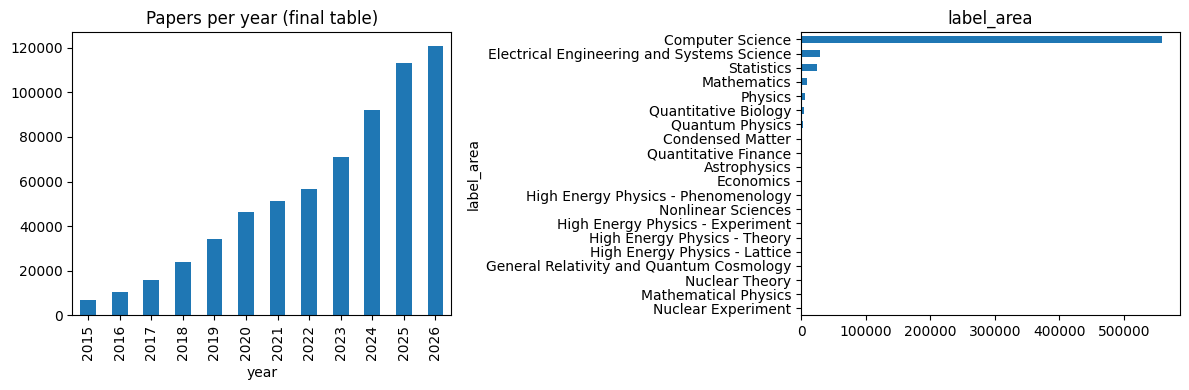

In [8]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df.groupby("year").size().plot.bar(ax=ax[0], title="Papers per year (final table)")
df["label_area"].value_counts().plot.barh(ax=ax[1], title="label_area").invert_yaxis()
plt.tight_layout(); plt.show()

### Technique and domain labels (derived from `categories`)

The rules live in `src/label_mapping.py` and use only the category codes, never the text:

- **technique labels** (Computer Vision, NLP, Robotics, ...; multi-label) are the target of the **classification** task;
  papers with only cs.AI / cs.LG / stat.ML get `General ML/AI`;
- **domain labels** (Physics & Astronomy, Life Sciences & Medicine, ...) are **not** a classification target: they are only
  an external reference to interpret and evaluate the **topic model**.

In [ ]:
import label_mapping as lm
lm.check_coverage()                  # every arXiv category code must be mapped
df = lm.add_labels(df)               # adds `technique_labels` and `domain_labels` ('|'-joined)
print(lm.label_report(df))

In [ ]:
# share of each technique label per year (proportions, not raw counts)
tech = lm.to_multihot(df["technique_labels"], lm.TECHNIQUE_CLASSES)
share = tech.groupby(df["year"]).mean().mul(100)
ax = share.plot(figsize=(9, 4), marker="o", title="Technique labels: % of papers per year")
ax.set_ylabel("% of papers"); ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

In [ ]:
# save the labels next to the dataset (not committed to git: data/ is ignored)
LABELS_CSV = str(OUTPUT_CSV).replace(".csv", "_labels.csv")
df[["arxiv_id", "technique_labels", "domain_labels"]].to_csv(LABELS_CSV, index=False)
print("saved ->", LABELS_CSV)

## Notes

- `categories` and `n_categories` contain the label (the primary category is one of the categories):
  **never use them as features** for classification.
- Labels are chosen by the authors and only partly reviewed by moderators: they are noisy.
- Category descriptions come from `src/arxiv_taxonomy.py` (copied from the official taxonomy on 2026-11-13).
  Codes that are not in the table appear in the summary printed at the end of the download.

In [9]:
#import pandas as pd

#CSV_PATH = "/content/drive/MyDrive/Txt_lab_data/arxiv_ai_abstracts.csv"   # change if needed
#df = pd.read_csv(CSV_PATH, dtype={"arxiv_id": str})   # arxiv_id as text: as a number "2510.10000" would become 2510.1

# ---- 1. Shape and types ---------------------------------------------------------------------
print("Rows x columns:", df.shape)
print(f"Memory: {df.memory_usage(deep=True).sum() / 1e6:.0f} MB\n")
print(df.dtypes.to_string())

# ---- 2. Missing values -----------------------------------------------------------------------
# (comment and journal_ref are optional fields: many empty values there are expected)
missing = pd.DataFrame({"null": df.isna().sum(),
                        "empty_string": (df == "").sum()}).astype(int)
missing["null_%"] = (100 * missing["null"] / len(df)).round(2)
print("\nMissing values per column:")
print(missing.to_string())

# ---- 3. Duplicates ---------------------------------------------------------------------------
print("\nDuplicates:")
print("  duplicated arxiv_id          :", df["arxiv_id"].duplicated().sum())
print("  fully duplicated rows        :", df.duplicated().sum())
print("  duplicated abstracts (exact) :", df["abstract"].duplicated().sum())
print("  duplicated titles (exact)    :", df["title"].duplicated().sum())

# ---- 4. Descriptive statistics ---------------------------------------------------------------
df["n_words"] = df["abstract"].str.split().str.len()
print("\nAbstract length (words):")
print(df["n_words"].describe().round(1).to_string())
print("\nPublished:", df["published"].min(), "->", df["published"].max())
print("n_categories per paper:")
print(df["n_categories"].describe().round(2).to_string())
print("\nPapers per year:")
print(df["year"].value_counts().sort_index().to_string())
print(f"\nprimary_is_generic_ai = True: {df['primary_is_generic_ai'].mean():.1%}")

# ---- 5. ALL primary categories (labels) with counts -----------------------------------------
labels = (df.groupby(["primary_category", "label_description", "label_area"]).size()
            .rename("count").reset_index().sort_values("count", ascending=False)
            .reset_index(drop=True))
labels["%"] = (100 * labels["count"] / len(df)).round(3)
labels["cumulative_%"] = labels["%"].cumsum().round(2)
print(f"\nDistinct primary categories: {len(labels)}")
print(f"  with < 100 papers: {(labels['count'] < 100).sum()} | with < 10 papers: {(labels['count'] < 10).sum()}")
with pd.option_context("display.max_rows", None, "display.width", 200, "display.max_colwidth", 60):
    display(labels)

Rows x columns: (643294, 13)
Memory: 1237 MB

arxiv_id                 float64
title                     object
abstract                  object
published                 object
year                       int64
categories                object
primary_category          object
label_description         object
label_area                object
n_categories               int64
primary_is_generic_ai       bool
comment                   object
journal_ref               object

Missing values per column:
                         null  empty_string  null_%
arxiv_id                    0             0    0.00
title                       0             0    0.00
abstract                    0             0    0.00
published                   0             0    0.00
year                        0             0    0.00
categories                  0             0    0.00
primary_category            0             0    0.00
label_description           0             0    0.00
label_area                  0

,primary_category,label_description,label_area,count,%,cumulative_%
0,cs.CV,Computer Vision and Pattern Recognition,Computer Science,160919,25.015,25.02
1,cs.LG,Machine Learning,Computer Science,145803,22.665,47.68
2,cs.CL,Computation and Language,Computer Science,88663,13.783,61.46
3,cs.RO,Robotics,Computer Science,45007,6.996,68.46
4,cs.AI,Artificial Intelligence,Computer Science,44238,6.877,75.34
5,stat.ML,Machine Learning,Statistics,20231,3.145,78.48
6,eess.IV,Image and Video Processing,Electrical Engineering and Systems Science,15841,2.462,80.94
7,cs.CR,Cryptography and Security,Computer Science,10660,1.657,82.60
8,cs.IR,Information Retrieval,Computer Science,7715,1.199,83.80
9,cs.NE,Neural and Evolutionary Computing,Computer Science,7461,1.160,84.96
